# LSTM y GRU frente a la red recurrente simple (PyTorch)

En la presentación **Memoria de largo plazo: LSTM y GRU** vimos que la red recurrente simple **olvida rápido**: con ventanas largas, el gradiente se desvanece al recorrer la cadena hacia atrás y le cuesta aprender de los días lejanos. Las celdas **LSTM** y **GRU** lo resuelven con **compuertas** que deciden qué guardar, qué olvidar y qué entregar.

En este notebook tomamos **exactamente el mismo problema** del notebook anterior (pronosticar los pasajeros del metro de Chicago del día siguiente a partir de las últimas 8 semanas) y cambiamos **solo la celda**: RNN, LSTM y GRU, con los mismos datos, las mismas ventanas, el mismo número de neuronas y la misma forma de entrenar. Así cualquier diferencia en el error se debe a la celda.

La carga de datos, las ventanas y la clase para entrenar son las del notebook anterior; aquí van sin explicación aparte.

## Etapa 1: Datos y ventanas (igual que en el notebook anterior)

In [1]:
import copy
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
data_dir = Path("data")
csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
if not csv_path.exists():
    data_dir.mkdir(exist_ok=True)
    tgz_path, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/ridership.tgz",
                                             data_dir / "ridership.tgz")
    with tarfile.open(tgz_path) as f:
        f.extractall(data_dir)

df = pd.read_csv(csv_path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date")
df = df.drop_duplicates()          # el archivo trae algunos días repetidos
rail = df["rail"]                  # solo nos interesa el metro
rail.tail()

date
2021-11-26    189694
2021-11-27    187065
2021-11-28    147830
2021-11-29    276090
2021-11-30    302349
Name: rail, dtype: int64

In [3]:
rail_train = torch.tensor(rail["2016-01":"2018-12"].values / 1e6, dtype=torch.float32)
rail_valid = torch.tensor(rail["2019-01":"2019-05"].values / 1e6, dtype=torch.float32)
rail_test = torch.tensor(rail["2019-06":"2019-12"].values / 1e6, dtype=torch.float32)
print(len(rail_train), len(rail_valid), len(rail_test))

class WindowDataset(Dataset):
    def __init__(self, series, window_length):
        self.series = series
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, idx):
        end = idx + self.window_length
        window = self.series[idx:end].unsqueeze(-1)  # (T, 1)
        target = self.series[end:end + 1]            # el día siguiente
        return window, target


window_length = 56
train_set = WindowDataset(rail_train, window_length)
# Para validar y probar, la primera ventana necesita los 56 días anteriores: los pegamos al inicio
valid_set = WindowDataset(torch.cat([rail_train[-window_length:], rail_valid]), window_length)
test_set = WindowDataset(torch.cat([rail_valid[-window_length:], rail_test]), window_length)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

x, y = next(iter(train_loader))
print("Entrada:", tuple(x.shape), " Etiqueta:", tuple(y.shape))

1096 151 214
Entrada: (32, 56, 1)  Etiqueta: (32, 1)


Como en el notebook anterior, cada ejemplo es una pareja **(X, y)**: X es la ventana $X = (x_1, x_2, \dots, x_{56})$ con los pasajeros de 56 días seguidos, e y es el número de pasajeros del día siguiente (el día 57). Cada fila de la tabla es un ejemplo:

In [ ]:
def windows_table(dataset, n=5, scale=1e6):
    # Una fila por ejemplo: columnas x_1 ... x_T (la entrada X) y la columna y (la etiqueta)
    rows = []
    for i in range(n):
        X, y = dataset[i]
        row = {f"x_{t + 1}": X[t, 0].item() * scale for t in range(len(X))}
        row.update({"y" if len(y) == 1 else f"y_{h + 1}": y[h].item() * scale for h in range(len(y))})
        rows.append(row)
    return pd.DataFrame(rows, index=[f"ejemplo {i + 1}" for i in range(n)]).round().astype(int)


with pd.option_context("display.max_columns", 12):
    display(windows_table(train_set))

La misma idea en una gráfica: el primer ejemplo, con los 56 valores de X en naranja y la y que debe pronosticar la red en verde.

In [ ]:
def plot_window(dataset, idx=0, scale=1e6):
    X, y = dataset[idx]
    T, H = len(X), len(y)
    t_x, t_y = np.arange(1, T + 1), np.arange(T + 1, T + H + 1)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.axvspan(0.5, T + 0.5, color="tab:orange", alpha=0.08)
    ax.plot(t_x, X[:, 0] * scale, "o-", color="tab:orange", ms=4, label=f"X: entrada ($x_1, x_2, \\dots, x_{{{T}}}$)")
    ax.plot(t_y, y * scale, "o", color="tab:green", ms=9,
            label="y: etiqueta (lo que se pronostica)")
    for t in (1, 2, T):  # nombres de algunos valores de X
        ax.annotate(f"$x_{{{t}}}$", (t, X[t - 1, 0] * scale), textcoords="offset points", xytext=(0, 9), ha="center")
    ax.annotate("$y$" if H == 1 else f"$y_1 \\dots y_{{{H}}}$", (t_y[0], y[0] * scale), textcoords="offset points",
                xytext=(0, 12), ha="center", color="tab:green", fontsize=12)
    ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(); ax.legend(loc="lower left")
    plt.show()
    print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))


plot_window(train_set)

## Etapa 2: Las tres redes, una al lado de la otra

Las tres redes tienen la misma forma: una capa recurrente lee la ventana, tomamos el estado del último paso y una capa densa da el pronóstico. En PyTorch, cambiar de celda es cambiar `nn.RNN` por `nn.LSTM` o `nn.GRU`: reciben los mismos argumentos y la misma entrada `(batch, T, 1)`.

La única diferencia al programarlas está en **lo que devuelven**:

| Celda | Llamada | Qué devuelve además de `outputs` |
|---|---|---|
| RNN | `outputs, h_n = self.rnn(X)` | `h_n`: el último estado oculto |
| GRU | `outputs, h_n = self.gru(X)` | `h_n`: igual que la RNN (la GRU tiene una sola memoria) |
| LSTM | `outputs, (h_n, c_n) = self.lstm(X)` | una **pareja**: el estado oculto `h_n` y el **estado de celda** `c_n`, la memoria de largo plazo que vimos en la presentación |

En los tres casos `outputs` tiene el estado oculto $h_t$ de cada paso, y `outputs[:, -1]` es el resumen de la ventana que va a la capa densa.

In [4]:
class RNNNet(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, h_n = self.rnn(X)            # una sola memoria: h
        return self.head(outputs[:, -1])


class LSTMNet(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, (h_n, c_n) = self.lstm(X)    # dos memorias: h (corto plazo) y c (largo plazo)
        return self.head(outputs[:, -1])


class GRUNet(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, h_n = self.gru(X)            # una sola memoria: h, controlada por compuertas
        return self.head(outputs[:, -1])

Comprobemos lo que devuelve cada capa con un minibatch de ventanas:

In [5]:
x, _ = next(iter(train_loader))
rnn, lstm, gru = RNNNet().rnn, LSTMNet().lstm, GRUNet().gru

outputs, h_n = rnn(x)
print("RNN : outputs", tuple(outputs.shape), " h_n", tuple(h_n.shape))
outputs, (h_n, c_n) = lstm(x)
print("LSTM: outputs", tuple(outputs.shape), " h_n", tuple(h_n.shape), " c_n", tuple(c_n.shape))
outputs, h_n = gru(x)
print("GRU : outputs", tuple(outputs.shape), " h_n", tuple(h_n.shape))

RNN : outputs (32, 56, 32)  h_n (1, 32, 32)
LSTM: outputs (32, 56, 32)  h_n (1, 32, 32)  c_n (1, 32, 32)
GRU : outputs (32, 56, 32)  h_n (1, 32, 32)


Las formas son las mismas; la LSTM solo agrega `c_n`. Lo que sí cambia es **cuántos parámetros** hay dentro de la celda. Como vimos en la presentación, cada compuerta es como una pequeña capa recurrente con sus propios pesos:

- **RNN:** 1 bloque (el cálculo de $h_t$).
- **GRU:** 3 bloques (compuerta de actualización, compuerta de reinicio y el candidato).
- **LSTM:** 4 bloques (compuertas de olvido, de entrada y de salida, y el candidato).

Con las mismas 32 neuronas, la GRU tiene unas 3 veces los parámetros de la RNN y la LSTM unas 4 veces:

In [6]:
NETS = {"RNN": RNNNet, "LSTM": LSTMNet, "GRU": GRUNet}
n_params = {cell: sum(p.numel() for p in net().parameters()) for cell, net in NETS.items()}
for name, n in n_params.items():
    print(f"{name:4s}: {n:5,} parámetros  ({n / n_params['RNN']:.1f} veces la RNN)")

RNN : 1,153 parámetros  (1.0 veces la RNN)
LSTM: 4,513 parámetros  (3.9 veces la RNN)
GRU : 3,393 parámetros  (2.9 veces la RNN)


## Etapa 3: La clase para entrenar

Es la clase `RidershipForecaster` del notebook anterior, con un solo cambio: recibe `cell` (`"RNN"`, `"LSTM"` o `"GRU"`) y con eso arma la red correspondiente del diccionario `NETS`. Todo lo demás (pérdida, optimizador, `train_epoch`, `evaluate`, `fit`, `predict`) es idéntico para las tres celdas.

In [7]:
class RidershipForecaster:
    def __init__(self, cell="RNN", hidden_size=32, lr=3e-3):
        # La red se arma dentro de la clase: RNNNet, LSTMNet o GRUNet
        self.net = NETS[cell](hidden_size=hidden_size).to(device)
        self.loss_fn = nn.HuberLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.scale = 1e6  # para reportar el MAE en personas por día
        self.history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_abs, n = 0.0, 0.0, 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = self.net(X)
            loss = self.loss_fn(y_pred, y)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(X)
            total_abs += (y_pred - y).abs().sum().item()
            n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * self.scale

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_abs, n = 0.0, 0.0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                y_pred = self.net(X)
                total_loss += self.loss_fn(y_pred, y).item() * len(X)
                total_abs += (y_pred - y).abs().sum().item()
                n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * self.scale

    def fit(self, train_loader, valid_loader, epochs=100):
        best_mae, best_state = float("inf"), None
        pbar = tqdm(range(epochs), desc="Entrenamiento", unit="época")
        for epoch in pbar:
            loss, mae = self.train_epoch(train_loader)
            val_loss, val_mae = self.evaluate(valid_loader)
            for key, value in zip(self.history, (loss, mae, val_loss, val_mae)):
                self.history[key].append(value)
            if val_mae < best_mae:  # guardamos los mejores pesos
                best_mae, best_state = val_mae, copy.deepcopy(self.net.state_dict())
            pbar.set_postfix(mae=f"{mae:,.0f}", val_mae=f"{val_mae:,.0f}", mejor_val_mae=f"{best_mae:,.0f}")
        self.net.load_state_dict(best_state)  # nos quedamos con los mejores pesos
        print(f"Mejor MAE de validación: {best_mae:,.0f}")
        return best_mae

    def predict(self, X):
        # Devuelve el pronóstico (en la escala de entrenamiento) para cada ventana
        self.net.eval()
        with torch.no_grad():
            return self.net(X.to(device)).cpu()

## Etapa 4: Entrenamiento con la misma configuración

Las tres redes se entrenan igual: 32 neuronas, la misma semilla, la misma tasa de aprendizaje y 100 épocas, guardando el mejor modelo según la validación.

In [8]:
forecasters, val_mae = {}, {}
for cell in NETS:
    print(f"=== {cell} ===")
    torch.manual_seed(42)
    forecasters[cell] = RidershipForecaster(cell=cell, hidden_size=32)
    val_mae[cell] = forecasters[cell].fit(train_loader, valid_loader, epochs=100)

=== RNN ===


Entrenamiento: 100%|██████████| 100/100 [00:02<00:00, 34.46época/s, mae=144,885, mejor_val_mae=45,469, val_mae=141,405]


Mejor MAE de validación: 45,469
=== LSTM ===


Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 30.75época/s, mae=47,106, mejor_val_mae=45,735, val_mae=48,075]


Mejor MAE de validación: 45,735
=== GRU ===


Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 31.95época/s, mae=38,866, mejor_val_mae=41,923, val_mae=44,097]


Mejor MAE de validación: 41,923


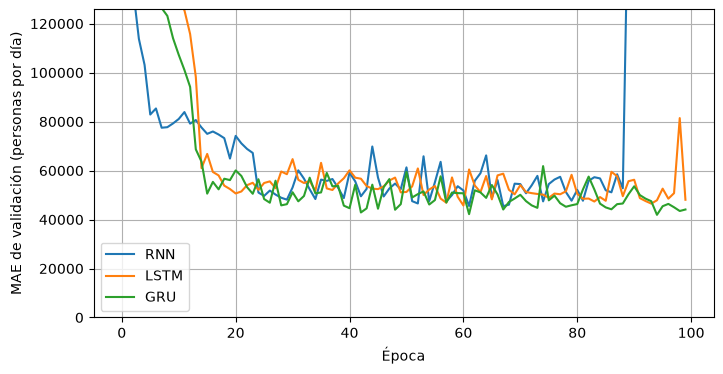

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, forecaster in forecasters.items():
    ax.plot(forecaster.history["val_mae"], label=name)
ax.set_ylim(0, 3 * min(val_mae.values()))
ax.set_xlabel("Época"); ax.set_ylabel("MAE de validación (personas por día)"); ax.grid(); ax.legend()
plt.show()

## Etapa 5: Métricas en el conjunto de prueba

Medimos las tres redes en **prueba** (junio a diciembre de 2019), días que ninguna vio, y las ponemos junto al **pronóstico ingenuo** (el mismo día de la semana pasada) como punto de referencia.

In [10]:
test_period = slice("2019-06", "2019-12")
naive_forecast = rail.shift(7)
naive_test_mae = (rail[test_period] - naive_forecast[test_period]).abs().mean()

summary = pd.DataFrame({
    "parámetros": pd.Series(n_params),
    "MAE validación": pd.Series(val_mae),
    "MAE prueba": pd.Series({name: f.evaluate(test_loader)[1] for name, f in forecasters.items()}),
})
summary.loc["Ingenuo (hace 7 días)"] = [0, np.nan, naive_test_mae]
summary["MAE prueba (% del promedio)"] = summary["MAE prueba"] / rail[test_period].mean() * 100
summary.round(1)

,parámetros,MAE validación,MAE prueba,MAE prueba (% del promedio)
RNN,1153,45469.5,38316.8,6.3
LSTM,4513,45734.6,42293.4,6.9
GRU,3393,41923.0,37423.7,6.1
Ingenuo (hace 7 días),0,NaN,62948.6,10.3


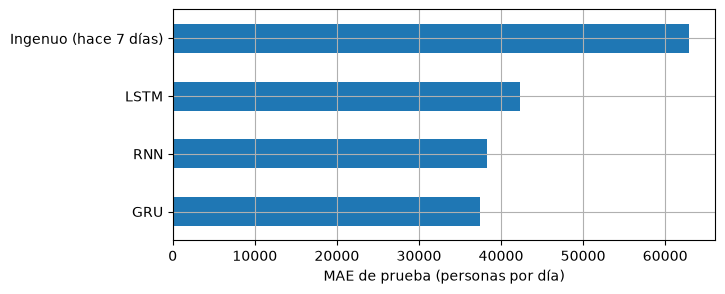

In [11]:
summary["MAE prueba"].sort_values().plot.barh(figsize=(7, 3), grid=True)
plt.xlabel("MAE de prueba (personas por día)")
plt.show()

Algunas cosas para observar (los números exactos cambian un poco en cada ejecución):

- Las tres redes deberían ganarle al pronóstico ingenuo.
- En la gráfica del entrenamiento, la RNN es la más inestable: en algunas épocas su error se dispara. Es el síntoma de los gradientes que se desvanecen o explotan al recorrer 56 pasos hacia atrás; las compuertas de LSTM y GRU hacen el entrenamiento más estable.
- LSTM y GRU suelen manejar mejor las ventanas largas, pero en una serie tan regular como esta la diferencia en el error es pequeña y no siempre a su favor (más parámetros no garantizan un mejor resultado). La ventaja crece cuando el patrón depende de cosas que pasaron muchos pasos atrás.
- La GRU suele quedar a la altura de la LSTM con menos parámetros; por eso es una buena primera opción.

Finalmente, los pronósticos de las tres redes sobre los primeros meses de prueba:

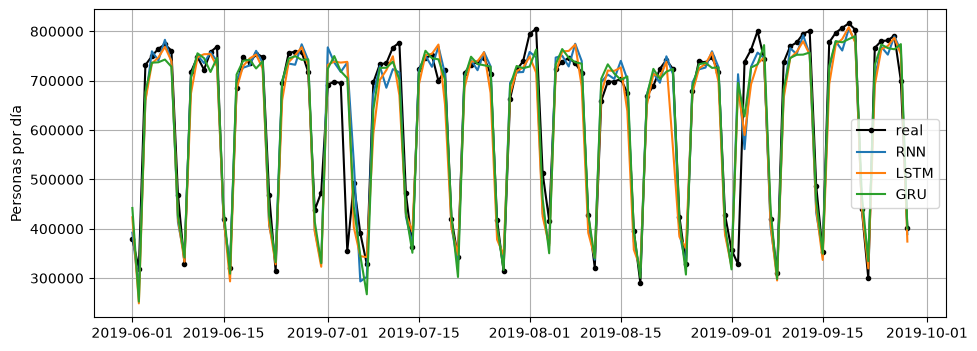

In [12]:
X_test = torch.stack([test_set[i][0] for i in range(len(test_set))])
dates = rail[test_period].index
n_days = 120

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(dates[:n_days], rail[test_period].values[:n_days], "k.-", label="real")
for name, forecaster in forecasters.items():
    y_pred = forecaster.predict(X_test).squeeze() * 1e6
    ax.plot(dates[:n_days], y_pred[:n_days], label=name)
ax.set_ylabel("Personas por día"); ax.grid(); ax.legend()
plt.show()

En el siguiente notebook usamos la GRU para pronosticar **varios días hacia adelante**.